<a href="https://colab.research.google.com/github/mirzabenny/Project/blob/master/HSD_using_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [100]:
import pandas as pd
import spacy
from tensorflow.keras.preprocessing.text import one_hot
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [101]:
df=pd.read_csv('/content/labeled_data.csv')

In [102]:
df.shape

(24783, 7)

In [103]:
# 0 - hate speech, 1 - offensive language, 2 - neither
df.head()

,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet
0,0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...


In [104]:
#deleting unwated columns
df.columns

Index(['Unnamed: 0', 'count', 'hate_speech', 'offensive_language', 'neither',
       'class', 'tweet'],
      dtype='object')

In [105]:
df.drop(columns=['Unnamed: 0', 'count', 'hate_speech', 'offensive_language', 'neither'],inplace=True)

In [106]:
df.head()

,class,tweet
0,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...


In [107]:
#Checking null values
df.isna().sum()

,0
class,0
tweet,0


In [108]:
df['tweet'].iloc[0]

"!!! RT @mayasolovely: As a woman you shouldn't complain about cleaning up your house. &amp; as a man you should always take the trash out..."

In [109]:
df['tweet'].iloc[100]

'"@ClicquotSuave: LMAOOOOOOOOOOO this nigga @Krillz_Nuh_Care http://t.co/AAnpSUjmYI" &lt;bitch want likes for some depressing shit..foh'

In [110]:
df['tweet'].iloc[1000]

'&#128514;&#128514;&#128514;&#128514;&#128514;&#128514;&#128514;"@betysweetcocker: That pussy is just....&#128561; imma assume she just had a baby like..the day before"'

In [111]:
#Data Cleaning, Deleting unwanted symbols and numeric data
df['processed_tweet']=df['tweet'].str.replace(r'[^a-zA-Z]',' ',regex=True)

In [112]:
df.head()

,class,tweet,processed_tweet
0,2,!!! RT @mayasolovely: As a woman you shouldn't...,RT mayasolovely As a woman you shouldn t...
1,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...,RT mleew boy dats cold tyga dwn ba...
2,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...,RT UrKindOfBrand Dawg RT sbaby...
3,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...,RT C G Anderson viva based she lo...
4,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...,RT ShenikaRoberts The shit you...


In [113]:
df['processed_tweet'].iloc[1000]

'                                                                 betysweetcocker  That pussy is just              imma assume she just had a baby like  the day before '

In [114]:
#Remove unwanted spaces
df['processed_tweet_2'] = df['processed_tweet'].str.replace(r'[\s]+',' ',regex=True)

In [115]:
df.head()

,class,tweet,processed_tweet,processed_tweet_2
0,2,!!! RT @mayasolovely: As a woman you shouldn't...,RT mayasolovely As a woman you shouldn t...,RT mayasolovely As a woman you shouldn t comp...
1,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...,RT mleew boy dats cold tyga dwn ba...,RT mleew boy dats cold tyga dwn bad for cuffi...
2,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...,RT UrKindOfBrand Dawg RT sbaby...,RT UrKindOfBrand Dawg RT sbaby life You ever ...
3,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...,RT C G Anderson viva based she lo...,RT C G Anderson viva based she look like a tr...
4,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...,RT ShenikaRoberts The shit you...,RT ShenikaRoberts The shit you hear about me ...


In [116]:
#deleting unwanted columns
df.drop(columns=['tweet','processed_tweet'],inplace=True)

In [117]:
df.head()

,class,processed_tweet_2
0,2,RT mayasolovely As a woman you shouldn t comp...
1,1,RT mleew boy dats cold tyga dwn bad for cuffi...
2,1,RT UrKindOfBrand Dawg RT sbaby life You ever ...
3,1,RT C G Anderson viva based she look like a tr...
4,1,RT ShenikaRoberts The shit you hear about me ...


In [118]:
#NLP import english module
nlp=spacy.load('en_core_web_sm')

In [119]:
#Lemmatization - to root word
def lemmatization(text):
  doc=nlp(text)
  lemmaList = [word.lemma_ for word in doc] #extracting every word and lemma_ converts to root form
  return ' '.join(lemmaList)

In [121]:
df['lemma_tweet'] = df['processed_tweet_2'].apply(lemmatization)

In [122]:
df['processed_tweet_2'].iloc[67]

' Allyhaaaaa Lemmie eat a Oreo amp do these dishes One oreo Lol'

In [123]:
df['lemma_tweet'].iloc[67]

'  Allyhaaaaa Lemmie eat a Oreo amp do these dish one oreo lol'

In [124]:
#Remove stop words
def remove_stopwords(text):
  doc = nlp(text)
  no_stop_word_list = [word.text for word in doc if not word.is_stop]
  return ' '.join(no_stop_word_list)

In [125]:
df['final_tweet'] = df['lemma_tweet'].apply(remove_stopwords)

In [28]:
df.head()

,class,processed_tweet_2,lemma_tweet,final_tweet
0,2,RT mayasolovely As a woman you shouldn t comp...,RT mayasolovely as a woman you shouldn t com...,RT mayasolovely woman shouldn t complain cl...
1,1,RT mleew boy dats cold tyga dwn bad for cuffi...,RT mleew boy dat cold tyga dwn bad for cuffi...,RT mleew boy dat cold tyga dwn bad cuffin d...
2,1,RT UrKindOfBrand Dawg RT sbaby life You ever ...,RT UrKindOfBrand Dawg RT sbaby life you ever...,RT UrKindOfBrand Dawg RT sbaby life fuck bi...
3,1,RT C G Anderson viva based she look like a tr...,RT C G Anderson viva base she look like a tr...,RT C G Anderson viva base look like tranny
4,1,RT ShenikaRoberts The shit you hear about me ...,RT ShenikaRoberts the shit you hear about I ...,RT ShenikaRoberts shit hear true faker bitc...


In [126]:
#In LSTM one-hot representation of every instance
vocab_size = 1000
one_hot_representation=[one_hot(words,vocab_size) for words in df['final_tweet']]

In [127]:
df['final_tweet'].iloc[100]

'   ClicquotSuave LMAOOOOOOOOOOO nigga Krillz Nuh Care http t co AAnpSUjmYI lt bitch want like depressing shit foh'

In [128]:
for i in range(4):
  print(one_hot_representation[i])

[882, 953, 3, 918, 833, 280, 389, 666, 879, 503, 333]
[882, 103, 408, 506, 267, 927, 54, 951, 530, 506, 209, 478, 770]
[882, 617, 13, 882, 584, 932, 775, 649, 323, 143, 555, 821]
[882, 977, 996, 115, 888, 526, 911, 486, 699]


In [129]:
#Padding - defaut sentence length
sentence_length=20
embedded_tweet=pad_sequences(one_hot_representation,padding='pre',maxlen=sentence_length)#adding 0 till it meet the length, pre padding

In [130]:
for i in range(4):
  print(embedded_tweet[i])

[  0   0   0   0   0   0   0   0   0 882 953   3 918 833 280 389 666 879
 503 333]
[  0   0   0   0   0   0   0 882 103 408 506 267 927  54 951 530 506 209
 478 770]
[  0   0   0   0   0   0   0   0 882 617  13 882 584 932 775 649 323 143
 555 821]
[  0   0   0   0   0   0   0   0   0   0   0 882 977 996 115 888 526 911
 486 699]


In [131]:
x = np.array(embedded_tweet)
y = np.array(df['class'])

In [132]:
df['class'].value_counts()

,count
class,
1,19190
2,4163
0,1430


In [133]:
#Highly imbalanced - oversample the class 0
smote = SMOTE(sampling_strategy='minority')
x,y = smote.fit_resample(x, y)


In [134]:
#train-test split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [135]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape #Has performed SMOTE, so more samples are there now

((34034, 20), (8509, 20), (34034,), (8509,))

In [136]:
# Stack LSTM -Creating models
dimension = 50
model=keras.Sequential([
    #embedding layer
    keras.layers.Embedding(vocab_size,dimension,input_length=sentence_length),
    #LSTM
    keras.layers.LSTM(100,return_sequences=True),
    keras.layers.LSTM(50,return_sequences=True),
    keras.layers.LSTM(50),
    #Output layer
    keras.layers.Dense(3,activation='softmax'),

])
model.build(input_shape=(None, sentence_length))

model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [137]:
model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_10 (Embedding)        │ (None, 20, 50)         │        50,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_30 (LSTM)                  │ (None, 20, 100)        │        60,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_31 (LSTM)                  │ (None, 20, 50)         │        30,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_32 (LSTM)                  │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 3)              │           153 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,953 (628.72 KB)

 Trainable params: 160,953 (628.72 KB)

 Non-trainable params: 0 (0.00 B)

In [138]:
model.fit(x_train,y_train,epochs=10,batch_size=32)

Epoch 1/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 46s 38ms/step - accuracy: 0.7518 - loss: 0.5669
Epoch 2/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 41s 37ms/step - accuracy: 0.8879 - loss: 0.3222
Epoch 3/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 42s 39ms/step - accuracy: 0.8989 - loss: 0.2914
Epoch 4/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 81s 38ms/step - accuracy: 0.9005 - loss: 0.2779
Epoch 5/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 41s 38ms/step - accuracy: 0.9092 - loss: 0.2558
Epoch 6/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 42s 39ms/step - accuracy: 0.9137 - loss: 0.2417
Epoch 7/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 81s 38ms/step - accuracy: 0.9204 - loss: 0.2249
Epoch 8/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 41s 38ms/step - accuracy: 0.9239 - loss: 0.2121
Epoch 9/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 40s 38ms/step - accuracy: 0.9329 - loss: 0.1913
Epoch 10/10
1064/1064 ━━━━━━━━━━━━━━━━━━━━ 40s 38ms/step - accuracy: 0.9376 - loss: 0.1763


In [142]:
loss,accuracy = model.evaluate(x_test,y_test)
print(f'Model Accuracy: {accuracy *100}')

266/266 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.8805 - loss: 0.3887
Model Accuracy: 87.70713210105896


In [143]:
pred = np.argmax(model.predict(x_test), axis=-1)

266/266 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step


In [144]:
y_test[:5]

array([1, 1, 0, 1, 2])

In [145]:
pred[:5]

array([1, 1, 0, 1, 2])

In [146]:
print(classification_report(y_test,pred))

              precision    recall  f1-score   support

           0       0.89      0.90      0.90      3812
           1       0.90      0.91      0.91      3807
           2       0.69      0.65      0.67       890

    accuracy                           0.88      8509
   macro avg       0.83      0.82      0.82      8509
weighted avg       0.88      0.88      0.88      8509



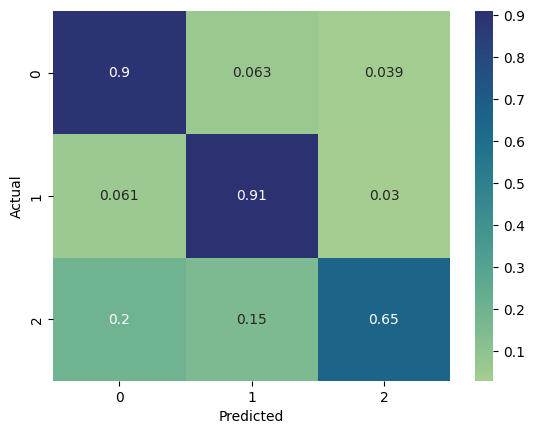

In [147]:
cf=confusion_matrix(y_test,pred,normalize='true')
sns.heatmap(cf,annot=True,cmap='crest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()